# AgriWatch Monitor — woda w winnicy (Condom, Gers)
Notatnik zarządczy całego potoku. Otwieraj z GitHub (Plik → Otwórz → GitHub), potem `Uruchom wszystko`.
GPU potrzebne tylko przy nowych scenach (SEN2SR).

Łańcuch: Sentinel-2, ERA5-Land i satelitarny SWI (Copernicus) → SEN2SR 2,5 m z kontrolą → indeksy winnicy →
statystyki 15 winnic (W3b) → anomalie i status dekadowy (logika EDO CDI) → walidacja na ISMN Condom → pogoda
(Météo-France) → testy W3b → biuletyn → **dashboard z kartami „Moja winnica” i „Woda w glebie”** → raport.

Stan i plan: `docs/STAN_I_PLAN.md`; „Moja winnica”: `docs/plans/W3b_plan_wdrozenia.md`, protokół
`docs/evidence/W3b_protokol_walidacji.md` (zarejestrowany przed liczeniem).
Klucze: tylko z `MyDrive/GeoWorldLook/secrets/` (np. `cdse.env`); notatnik nie wypisuje ich treści.
Wyniki: `MyDrive/GeoWorldLook/agriwatch/data/05_Final_Outputs/agriwatch/` i tabele `data/registry/gwl_*.csv`.


## 1. Dysk Google i kod z GitHub


In [1]:
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False

REPO_URL = 'https://github.com/geoworldlook/agriscreen.git'
PROJECT_DIR = '/content/drive/MyDrive/GeoWorldLook/agriwatch'
if IN_COLAB:
    if not os.path.exists(os.path.join(PROJECT_DIR, '.git')):
        os.makedirs(os.path.dirname(PROJECT_DIR), exist_ok=True)
        !git clone {REPO_URL} "{PROJECT_DIR}"
    # Lokalne zmiany w kodzie (np. zapisany notatnik) blokowały `pull --ff-only` i kod zostawał stary:
    # odkładamy je do stash (do odzyskania: git stash list / git stash pop), potem pull.
    !git -C "{PROJECT_DIR}" stash push -q -m "colab-autostash" || true
    !git -C "{PROJECT_DIR}" pull --ff-only
    !git -C "{PROJECT_DIR}" log -1 --format="Kod: %h %ci %s"
    if os.popen(f'git -C "{PROJECT_DIR}" rev-parse HEAD').read() != os.popen(f'git -C "{PROJECT_DIR}" rev-parse origin/main').read():
        print('[UWAGA] Kod na Dysku różni się od origin/main — wyniki będą z innej wersji kodu.')
else:
    PROJECT_DIR = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath('.')
os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
import importlib
sys.modules.setdefault('imp', importlib)
try:
    %load_ext autoreload
    %autoreload 2
except Exception as e:
    print(f'[INFO] autoreload pominięty ({e})')
print('Projekt:', PROJECT_DIR)


Mounted at /content/drive
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (94/94), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 81 (delta 54), reused 52 (delta 28), pack-reused 0 (from 0)
Unpacking objects: 100% (81/81), 1.27 MiB | 108.00 KiB/s, done.
From https://github.com/geoworldlook/1_geoworldlook-agriscreen
   54cc586..a52d7a1  main       -> origin/main
   54cc586..a52d7a1  claude/new-session-dxyke7 -> origin/claude/new-session-dxyke7
Updating 54cc586..a52d7a1
Fast-forward
 assets/leaflet-1.9.4.css             |  664 ++++++++++++++++++
 build_colab_master.py                |   21 +-
 build_story_notebook.py              |  229 ++++++
 docs/ARCHITEKTURA.md                 |    5 +
 docs/STAN_I_PLAN.md                  |   55 +-
 docs/evidence/W3b_wyniki.md          |  144 ++++
 docs/evidence/W3c_protokol_strefy.md |  132 ++++
 docs/evidence/karta_wynikow.md       |   10 +
 docs/plans/Plan_W3b_moja_winnica.md  |    3 +-
 docs/plans/W3b_

## 2. Środowisko: pakiety, GEE, rejestr, konfiguracja


In [2]:
from step_05_colab_run import (setup_runtime, monitor_config, run_task, run_history, registry_summary,
                               task_ingest_s2, task_ingest_era5, task_ingest_swi, task_scene_stats, task_anomalies,
                               task_validate, task_weather, task_ref_validate, task_bulletin, task_dashboard,
                               task_summary, task_parcel_stats, task_parcel_tests, task_parcel_anomalies, task_zones,
                               task_panel)
from step_06_dashboard import show_dashboard
rt = setup_runtime(PROJECT_DIR, gee_project='ee-geoworldlook', pull=False)
cfg = monitor_config(rt)   # zmiany: monitor_config(rt, {'VINEYARDS': {'VINEYARD_06': 6, 'VINEYARD_07': 7}})



earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.). Uruchamianie procedury autoryzacji...


## 3. Dane: rastry Sentinel-2 (przyrostowo) i ERA5-Land 1991 → dziś


In [3]:
run_task(rt, 'ingest_s2', task_ingest_s2, rt, cfg)
run_task(rt, 'ingest_era5', task_ingest_era5, rt, cfg)


[SKIPPED] ingest_s2 (13.6 s) 419 scen na Dysku, 0 nowych
[OK] ingest_era5 (13.4 s) ERA5-Land: 13063 dni do 2026-10-06


{'message': 'ERA5-Land: 13063 dni do 2026-10-06'}

## 3b. Satelitarny SWI — pobieranie (Plan v9 W3a)
CLMS Soil Water Index z Copernicus Data Space (klucze z `secrets/cdse.env`, bez wypisywania): **0,1° v4** (radar ASCAT,
I 2007 – dziś, jedna wersja produktu) do wiersza satelity na karcie wody i **1 km v2** (od 13 VII 2025), zbierany bez
normy, dopóki nie ma dłuższej historii. Pierwsze uruchomienie pobiera archiwum od 2007 r. (kilka minut), kolejne tylko
ostatnie dni. Metoda: `docs/evidence/W3a_SWI_1km_satelita.md` §0 (T = 15, norma 2007–2024).


In [4]:
run_task(rt, 'ingest_swi', task_ingest_swi, rt, cfg)


[OK] ingest_swi (36.1 s) v4_0.1deg: 6688 dni z danymi 2007-01-02…2026-10-19, z flagą producenta 0; v2_1km: 457 dni z danymi 2025-07-13…2026-10-17, z flagą producenta 0


{'message': 'v4_0.1deg: 6688 dni z danymi 2007-01-02…2026-10-19, z flagą producenta 0; v2_1km: 457 dni z danymi 2025-07-13…2026-10-17, z flagą producenta 0'}

## 4. Indeksy winnicy i stacji: 10 m oraz SEN2SR 2,5 m (kontrola H-SR0/H-SR1, bez zastępstwa interpolacją)


In [5]:
run_task(rt, 'scene_stats', task_scene_stats, rt, cfg)


[SKIPPED] scene_stats (2.4 s) 10 m: 0 nowych scen; SR: 0 scen, NDVI 2,5 m przyjęte w 0, NDMI 2,5 m w 0, CRSWIR 2,5 m w 0 (próg 20 m: specyfikacja L2A × 1.5); pokrycie SR (detekcja): 419/419 scen przetworzonych, 404 przyjętych, 0 w kolejce


{'skipped': True,
 'message': '10 m: 0 nowych scen; SR: 0 scen, NDVI 2,5 m przyjęte w 0, NDMI 2,5 m w 0, CRSWIR 2,5 m w 0 (próg 20 m: specyfikacja L2A × 1.5); pokrycie SR (detekcja): 419/419 scen przetworzonych, 404 przyjętych, 0 w kolejce',
 'registry': {}}

## 4b. Moja winnica: statystyki 15 winnic (W3b)
Średnie wskaźników (NDVI, NDMI, NDRE, CRSWIR) i pasm B04, B06, B8A, B12 dla wszystkich 15 winnic, z pasem 20 m od
brzegu odciętym (protokół W3b §1). Liczone z archiwum na Dysku, bez pobierania i bez GPU. Pierwsze uruchomienie
przelicza całe archiwum (ok. 5–15 min, zapis co 25 scen, więc przerwana sesja wznawia się sama), kolejne tylko nowe
sceny. Komunikat podaje, ile winnic spełnia próg 40 pikseli (oczekiwane 13 z 15).


In [6]:
run_task(rt, 'parcel_stats', task_parcel_stats, rt, cfg)


[SKIPPED] parcel_stats (1.1 s) 0 scen przeliczonych; 419 scen w S2_DIR (ostatnia 2026-10-18); winnice z QC (≥ 40 pikseli 10 m po pasie 20 m): 13/15; poniżej progu: VINEYARD_16 (19 px), VINEYARD_18 (16 px)


{'skipped': True,
 'message': '0 scen przeliczonych; 419 scen w S2_DIR (ostatnia 2026-10-18); winnice z QC (≥ 40 pikseli 10 m po pasie 20 m): 13/15; poniżej progu: VINEYARD_16 (19 px), VINEYARD_18 (16 px)'}

## 5. Anomalie, status, walidacja, przymrozki i upały
`weather`: dane dobowe Météo-France (Gers, Lot-et-Garonne) i ERA5-Land w punktach najbliższych stacji — walidacja
Tmin, Tmax, opadu i SPI oraz kalibracja progów przymrozku i upału. Pierwsze uruchomienie pobiera ERA5 dla stacji
(kilka minut), kolejne korzystają z cache.


In [7]:
run_task(rt, 'anomalies', task_anomalies, rt, cfg)
run_task(rt, 'validate', task_validate, rt, cfg)
run_task(rt, 'weather', task_weather, rt, cfg)


[OK] anomalies (8.4 s) VINEYARD_06 2026-09-30: alert (SPI1=-2.4;SPI3=-2.8;SMA_RZ=-1.7;VEG_Z=-1.5(S2SR_2.5m,9d)); gwl_anomalies: +0/~0, gwl_status: +0/~0
[OK] validate (13.0 s) 50 metryk; R anomalii 0-100 cm vs 20-30 cm = 0.58; gwl_validation_metrics: +0/~0
[OK] weather (58.2 s) 3 stacji MF (CONDOM 0 km, BEAUCAIRE 15 km, REAUP 18 km); progi ERA5: przymrozek Tmin ≤ +0.00 °C (nominalny (za mało zdarzeń do kalibracji na stacji CONDOM: 5)), upał Tmax ≥ 35.50 °C (skalibrowany na stacji CONDOM (59 dni ze zdarzeniem, CSI +0.06 na latach kalibracji)); 114 metryk; gwl_validation_metrics: +0/~0


{'message': '3 stacji MF (CONDOM 0 km, BEAUCAIRE 15 km, REAUP 18 km); progi ERA5: przymrozek Tmin ≤ +0.00 °C (nominalny (za mało zdarzeń do kalibracji na stacji CONDOM: 5)), upał Tmax ≥ 35.50 °C (skalibrowany na stacji CONDOM (59 dni ze zdarzeniem, CSI +0.06 na latach kalibracji)); 114 metryk',
 'registry': {'gwl_validation_metrics':          site_id       product    reference         segment         period  \
  0    MF_32107006    ERA5L_TMIN  MF_32107006           daily            all   
  1    MF_32107006    ERA5L_TMIN  MF_32107006           daily            all   
  2    MF_32107006    ERA5L_TMIN  MF_32107006           daily            all   
  3    MF_32107006    ERA5L_TMIN  MF_32107006           daily         season   
  4    MF_32107006    ERA5L_TMIN  MF_32107006           daily         season   
  ..           ...           ...          ...             ...            ...   
  109  MF_47221001  ERA5L_PRECIP  MF_47221001  SPI1<=-2_dekad  ref 1991-2020   
  110  MF_47221001  ERA5L_

## 5b. Walidacja na stacjach referencyjnych (Plan v9 W2 + REF)
Jeden protokół, zarejestrowany przed liczeniem (`docs/evidence/W2_REF_protokol_walidacji.md`, D-083): ERA5-Land
0–100 cm i satelitarny SWI wobec pomiarów w gruncie na trzech miejscach — **Condom** (ISMN 20–30 cm po kontroli
czujników A4), **Auradé** w Gers (ICOS, 2019–2025) i **Lusignan** (ICOS, dane bieżące). Pierwsze uruchomienie pobiera
dane ICOS oraz ERA5 i SWI w punktach stacji (kilkanaście minut), kolejne korzystają z cache. Wyniki w raporcie (sekcja 7)
i w `validation_reference.csv`. **Prześlij wynik** — na jego podstawie uzupełnimy „Na ile ufać” na karcie.


In [8]:
run_task(rt, 'ref_validate', task_ref_validate, rt, cfg)


[OK] ref_validate (236.3 s) FR-Aur (anomaly_clim): ERA5L_SM_RZ R = 0.57, SWI_v4_T015 R = 0.52; FR-Lus (anomaly_35d): ERA5L_SM_RZ R = 0.68, SWI_v4_T015 R = 0.53; SMOSMANIA_Condom (anomaly_clim): ERA5L_SM_RZ R = 0.57, SWI_v4_T015 R = 0.57; gwl_validation_metrics: +0/~48


{'message': 'FR-Aur (anomaly_clim): ERA5L_SM_RZ R = 0.57, SWI_v4_T015 R = 0.52; FR-Lus (anomaly_35d): ERA5L_SM_RZ R = 0.68, SWI_v4_T015 R = 0.53; SMOSMANIA_Condom (anomaly_clim): ERA5L_SM_RZ R = 0.57, SWI_v4_T015 R = 0.57',
 'registry': {'gwl_validation_metrics':               site_id      product            reference          segment  \
  0    SMOSMANIA_Condom  ERA5L_SM_RZ    ISMN_20_30cm_A4W1     anomaly_clim   
  1    SMOSMANIA_Condom  ERA5L_SM_RZ    ISMN_20_30cm_A4W1     anomaly_clim   
  2    SMOSMANIA_Condom  ERA5L_SM_RZ    ISMN_20_30cm_A4W1      anomaly_35d   
  3    SMOSMANIA_Condom  ERA5L_SM_RZ    ISMN_20_30cm_A4W1      anomaly_35d   
  4    SMOSMANIA_Condom  ERA5L_SM_RZ    ISMN_20_30cm_A4W1  class_agreement   
  ..                ...          ...                  ...              ...   
  315            FR-Lus  SWI_v4_T040  ICOS_FR-Lus_0_100cm      anomaly_35d   
  316            FR-Lus  SWI_v4_T040  ICOS_FR-Lus_0_100cm  class_agreement   
  317            FR-Lus  SWI_v4_T040

## 5c. Moja winnica: testy zamrożone i anomalie działek (W3b) — prześlij wynik
`parcel_tests` liczy testy według zarejestrowanego protokołu (`docs/evidence/W3b_protokol_walidacji.md`) na scenach
do daty zamrożenia (pierwsze uruchomienie zapisuje ją w `w3b_freeze.json`): T1 kalibracja, T2 szum, **T3 zgodność
roślinności okolicy z czujnikiem w gruncie (kryterium zdania 3)**, wariant wielopasmowy (kryterium przyjęcia) i
przeliczone wartości „przed” z F4. Kolejne uruchomienia zwracają „skipped” — liczby są zamrożone.
`parcel_anomalies` liczy anomalie wszystkich winnic do karty bieżącej.
**Prześlij komunikat `parcel_tests` i plik `w3b_tests.csv`** — na nich powstanie notatka wyników W3b.


In [9]:
run_task(rt, 'parcel_tests', task_parcel_tests, rt, cfg)
run_task(rt, 'parcel_anomalies', task_parcel_anomalies, rt, cfg)


[OK] parcel_tests (15.0 s) zamrożenie 2026-10-18 (419 scen, w3b_freeze.json); T3 ρ = 0.55 [-0.02; 1.00] — niespełnione (nierozstrzygnięty); wariant wielopasmowy: nieprzyjęty; T1 28.0% [4.4; 51.7] — nie wykryto grubego rozkalibrowania; gwl_validation_metrics: +0/~0
[OK] parcel_anomalies (7.0 s) 15 winnic (13 z QC), 4498 scen z z_woda, dni z 2 scenami: 24, sezony z flagą: 4; VINEYARD_06 2026-10-14: z_woda -1.37


{'message': '15 winnic (13 z QC), 4498 scen z z_woda, dni z 2 scenami: 24, sezony z flagą: 4; VINEYARD_06 2026-10-14: z_woda -1.37'}

## 5d. Strefa gorsza niż zwykle (W3c) — prześlij wynik
Według zarejestrowanego protokołu (`docs/evidence/W3c_protokol_strefy.md`, D-090): w każdej winnicy piksel minus
mediana działki (wygładzone do 30 m), porównane z tym samym miejscem w 5 poprzednich latach. Próg mapy wyznacza test
szumu na parach zdjęć bez deszczu. Warstwa „Zones vs usual” trafia do panelu **tylko po spełnieniu trzech warunków**
(§6). Pierwsze uruchomienie czyta całe archiwum (kilka–kilkanaście minut, zapis co 50 scen), kolejne tylko nowe sceny;
data zamrożenia testów trafia do `w3c_freeze.json`.
**Prześlij komunikat `zones` i plik `w3c_tests.csv`** — na nich powstanie notatka wyników W3c.


In [10]:
run_task(rt, 'zones', task_zones, rt, cfg)


[OK] zones (73.8 s) 13 winnic, 419 scen w magazynie (+419, pominięte z inną siatką: 0); zamrożenie 2026-10-18; NDVI: nie pokazujemy — 3: udział komórek w strefach (gleba w normie) górna 20.9% > 5%; NDMI: nie pokazujemy — 2: MDC95 górna 0.029 ≥ ½ rozstępu działki 0.025; 3: udział komórek w strefach (gleba w normie) górna 20.6% > 5%


{'message': '13 winnic, 419 scen w magazynie (+419, pominięte z inną siatką: 0); zamrożenie 2026-10-18; NDVI: nie pokazujemy — 3: udział komórek w strefach (gleba w normie) górna 20.9% > 5%; NDMI: nie pokazujemy — 2: MDC95 górna 0.029 ≥ ½ rozstępu działki 0.025; 3: udział komórek w strefach (gleba w normie) górna 20.6% > 5%'}

## 6. Biuletyn i dashboard winnicy
Od góry: **karta „Moja winnica”** (gleba w okolicy, wskaźnik wody w roślinności Twojej działki wobec jej historii,
okolica — tylko po spełnionym kryterium testu), **karta „Woda w glebie”** (kategoria suszy, niedobór, miejsce wśród
lat, od kiedy, opad, prawdopodobieństwo, „Na ile ufać”), krzywa sezonu, pogoda, prognoza, przymrozki i upały; niżej
„Roślinność działki (informacyjnie)” (mapa NDVI, kondycja) i „Szczegóły” (status EDO, wiarygodność, matryca sygnałów,
ostatnie lata). Biuletyn (`bulletin.md`, `agriwatch_latest.json`) powstaje po testach W3b, więc zawiera kartę działki.
Plik: `data/05_Final_Outputs/agriwatch/dashboard.html` (można otworzyć w przeglądarce z Dysku).


[OK] bulletin (27.0 s) data/05_Final_Outputs/agriwatch/agriwatch_latest.json, data/05_Final_Outputs/agriwatch/bulletin.md, data/05_Final_Outputs/agriwatch/season_2022.png, data/05_Final_Outputs/agriwatch/last_12_months.png, data/05_Final_Outputs/agriwatch/last_5_years.png, data/05_Final_Outputs/agriwatch/season_trajectory.png, data/05_Final_Outputs/agriwatch/signal_matrix.png
[OK] dashboard (13.5 s) data/05_Final_Outputs/agriwatch/dashboard.html



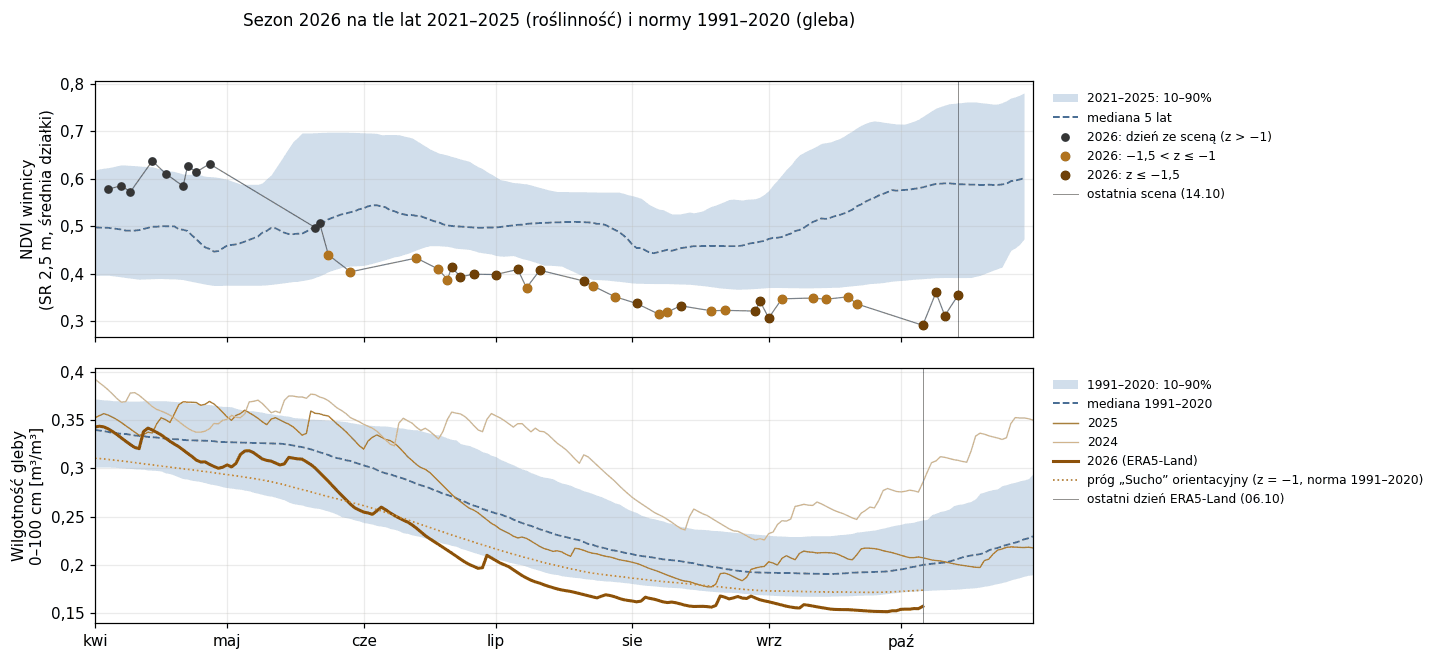
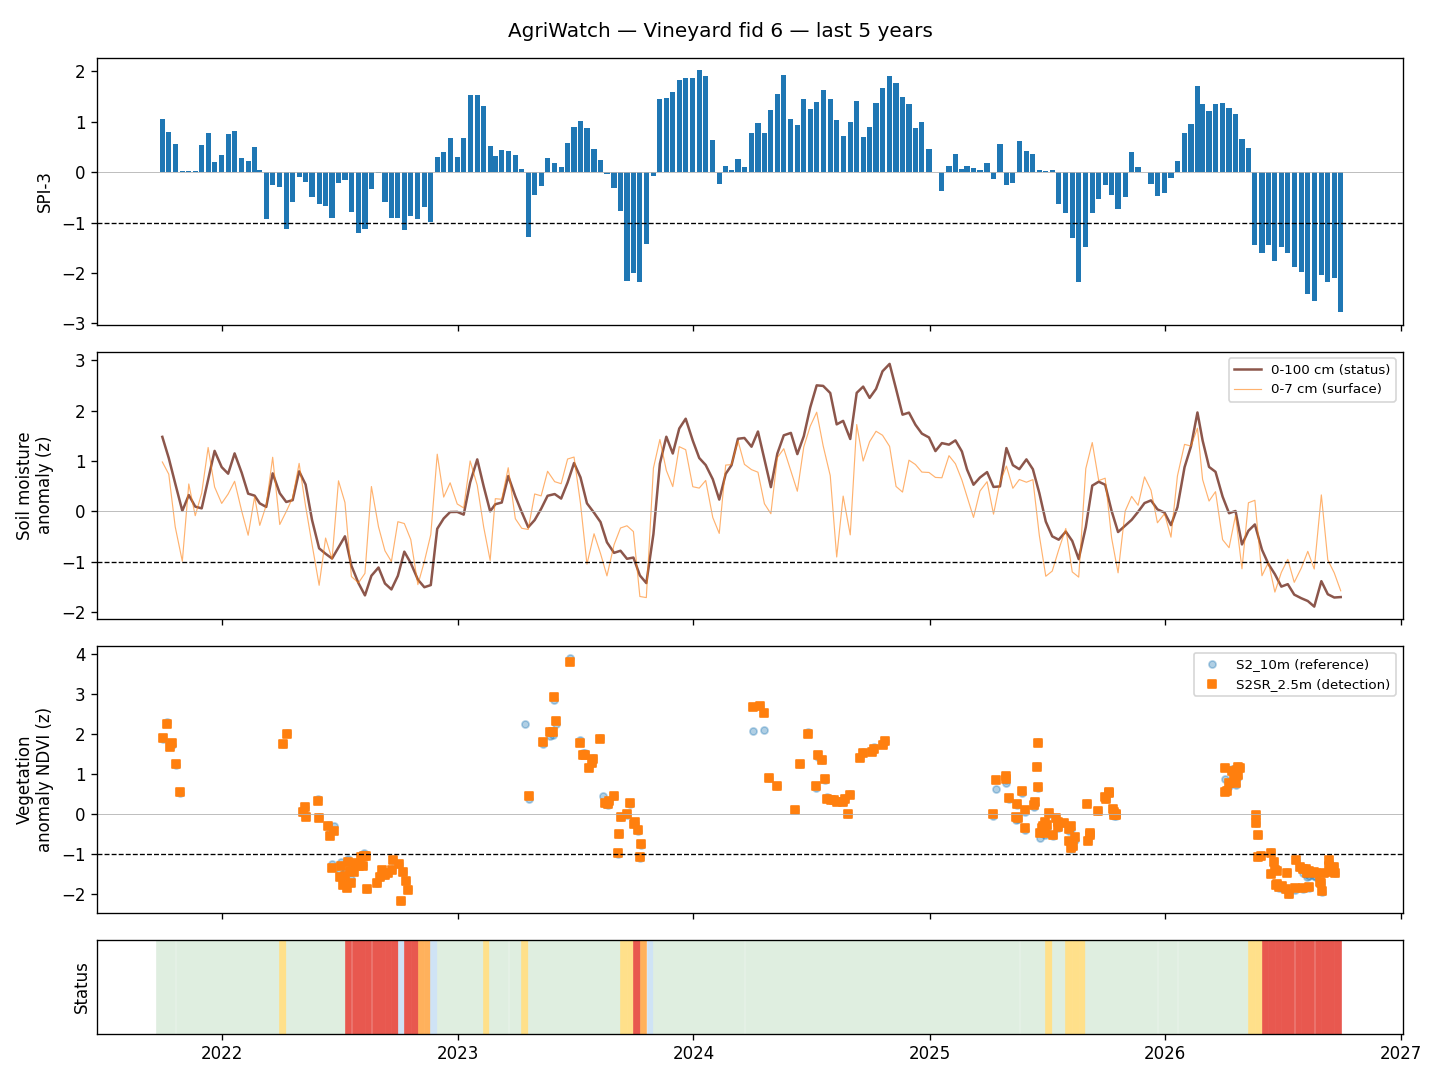

In [11]:
run_task(rt, 'bulletin', task_bulletin, rt, cfg)
run_task(rt, 'dashboard', task_dashboard, rt, cfg)
p = os.path.join(cfg['OUTPUT_DIR'], 'dashboard.html')
if os.path.exists(p):
    show_dashboard(p)
else:
    print('Dashboard nie powstał — sprawdź komunikat zadania powyżej.')


## 6b. Panel AgriScreen — 15 winnic (po angielsku, do publikacji na blogu)
Układ jak Wago (ESA WineEO): lista winnic, mapa na zdjęciu satelitarnym Esri z półprzezroczystą warstwą — piksele
10 m (NDVI, NDRE, NDMI), strefy wobec reszty działki, **strefy wobec zwykłego stanu (W3c, tylko po przejściu testu)**
albo cała działka wobec własnej historii; statystyki, gleba, pogoda (prognoza Open-Meteo), karta, sezon i „How far to
trust it”. Plik `panel.html` (Leaflet z unpkg, reszta w pliku) trafia na blog GeoWorldLook; `panel_data.json` czyta
notatnik `notebooks/AgriScreen_story.ipynb`.


In [12]:
run_task(rt, 'panel', task_panel, rt, cfg)
p = os.path.join(cfg['OUTPUT_DIR'], 'panel.html')
if os.path.exists(p):
    show_dashboard(p, height=3600)


[OK] panel (8.3 s) data/05_Final_Outputs/agriwatch/panel.html (973 kB)


## 7. Raport z uruchomienia (do analizy)
`run_summary.md` — wersje, konfiguracja, pokrycie danych, kontrola SR, **karty „Woda w glebie” i „Moja winnica”
z „Na ile ufać”, testy W3b**, status per rok, walidacja, pogoda, błędy.
**Po każdym większym uruchomieniu prześlij ten plik** (albo wklej jego treść) — na nim opieramy wnioski.


In [13]:
run_task(rt, 'summary', task_summary, rt, cfg)
print(open(os.path.join(cfg['OUTPUT_DIR'], 'run_summary.md'), encoding='utf-8').read())


[OK] summary (10.5 s) data/05_Final_Outputs/agriwatch/run_summary.md (39 kB)
# AgriWatch — raport z uruchomienia 2026-10-20T09:49:06Z

Commit `a52d7a1+dirty` · urządzenie: cpu · sen2sr 0.8.5 · torch 2.11.0+cpu

## Dane
{"s2_scenes": 419, "s2_first": "20160411", "s2_last": "20261018", "era5_last_day": "2026-10-06"}

## Konfiguracja
{"MAIN_SITE": "VINEYARD_06", "VEG_PRODUCT": "S2SR_2.5m", "VEG_INDEX": "ndvi", "S2_MONTHS": [4, 10], "S2_CLOUD_MAX_AOI": 40, "THR_SPI1": -2.0, "THR_SPI3": -1.0, "THR_SMA": -1.0, "THR_VEG": -1.0, "SR_MAX_CONSISTENCY_RMSE": 0.01, "SR_20M_SPEC_FACTOR": 1.5, "SR_MIN_DETAIL_RATIO": 0.02, "SR_MAX_SCENES_PER_RUN": 150}

## Super-resolution (kontrola qc4)
| zmienna | wartość | accept_rate | median | p90 |
|---|---|---|---|---|
| qc_version | qc4 |  |  |  |
| scenes_checked | 419 |  |  |  |
| scenes | 419 |  |  |  |
| sr_done | 419 |  |  |  |
| sr_ok |  | 0.964 |  |  |
| remaining | 0 |  |  |  |
| consistency_rmse_max |  |  | 0.0034 | 0.0042 |
| consistency_rmse_max_20

## 8. Rejestr i historia uruchomień


In [14]:
display(registry_summary(rt))
display(run_history(rt, n=10))


,table,rows,size_kb
0,gwl_sites,3,2.2
1,gwl_observations,95668,12814.3
2,gwl_anomalies,9017,1330.7
3,gwl_validation_metrics,971,161.1
4,gwl_calibrations,17,2.3
5,gwl_status,1161,264.5
6,gwl_runs,186,143.8


,run_id,task,status,duration_s,n_new_rows,git_commit,message
0,20261020T094902Z_summary,summary,ok,10.5,0,a52d7a1+dirty,data/05_Final_Outputs/agriwatch/run_summary.md...
1,20261020T094854Z_panel,panel,ok,8.3,0,a52d7a1+dirty,data/05_Final_Outputs/agriwatch/panel.html (97...
2,20261020T094840Z_dashboard,dashboard,ok,13.5,0,a52d7a1+dirty,data/05_Final_Outputs/agriwatch/dashboard.html
3,20261020T094813Z_bulletin,bulletin,ok,27.0,0,a52d7a1+dirty,data/05_Final_Outputs/agriwatch/agriwatch_late...
4,20261020T094659Z_zones,zones,ok,73.8,0,a52d7a1+dirty,"13 winnic, 419 scen w magazynie (+419, pominię..."
5,20261020T094652Z_parcel_anomalies,parcel_anomalies,ok,7.0,0,a52d7a1+dirty,"15 winnic (13 z QC), 4498 scen z z_woda, dni z..."
6,20261020T094637Z_parcel_tests,parcel_tests,ok,15.0,0,a52d7a1+dirty,"zamrożenie 2026-10-18 (419 scen, w3b_freeze.js..."
7,20261020T094241Z_ref_validate,ref_validate,ok,236.3,0,a52d7a1+dirty,"FR-Aur (anomaly_clim): ERA5L_SM_RZ R = 0.57, S..."
8,20261020T094133Z_weather,weather,ok,58.2,0,a52d7a1+dirty,"3 stacji MF (CONDOM 0 km, BEAUCAIRE 15 km, REA..."
9,20261020T094120Z_validate,validate,ok,13.0,0,a52d7a1+dirty,50 metryk; R anomalii 0-100 cm vs 20-30 cm = 0...
